# Simple Sentiment Analysis
We gebruiken [TextBlob](https://pypi.org/project/textblob/0.9.0/) om teksten te analyseren:<br>
https://textblob.readthedocs.io/en/dev/



In [ ]:
from textblob import TextBlob

We maken een 'sentiment analysis'-functie:

In [ ]:
def sentiment_analysis(text):
  # Create a TextBlob object
  blob = TextBlob(text)

  # Calculate the sentiment scores
  sentiment = blob.sentiment
  polarity = sentiment.polarity
  subjectivity = sentiment.subjectivity

  # Classify the polarity score as positive, negative, or neutral
  if polarity > 0:
    sentiment = 'positive'
  elif polarity == 0:
    sentiment = 'neutral'
  else:
    sentiment = 'negative'

  # Print the results
  print(f'Text: {text}')
  print(f'Sentiment: {sentiment}')
  print(f'Polarity: {polarity}')
  print(f'Subjectivity: {subjectivity}')

En we testen de functie:

In [ ]:
# Test the sentiment analysis function
sentiment_analysis('I love this movie! It was so much fun')
sentiment_analysis('I hated this movie. It was so boring.')
sentiment_analysis('I thought the movie was just okay.')

Text: I love this movie! It was so much fun
Sentiment: positive
Polarity: 0.4625
Subjectivity: 0.4
Text: I hated this movie. It was so boring.
Sentiment: negative
Polarity: -0.95
Subjectivity: 0.85
Text: I thought the movie was just okay.
Sentiment: positive
Polarity: 0.5
Subjectivity: 0.5


This code defines a function sentiment_analysis that takes in a string of text and calculates the sentiment scores using the TextBlob library.<br>

The polarity score is a value between -1 and 1 that indicates the sentiment of the text, with -1 being the most negative, 0 being neutral, and 1 being the most positive.<br>

The subjectivity score is a value between 0 and 1 that indicates the subjectivity of the text, with 0 being very objective and 1 being very subjective.<br>

The function then classifies the polarity score as either positive, negative, or neutral, and prints out the text, sentiment, polarity, and subjectivity scores.

Werkt deze functie ook met Nederlandse teksten?

In [ ]:
sentiment_analysis('Ik vind deze minor buitengewoon en bijzonder goed. Ik word er erg blij van.')

Text: Ik vind deze minor buitengewoon en bijzonder goed. Ik word er erg blij van.
Sentiment: negative
Polarity: -0.05
Subjectivity: 0.2


Het lijkt er niet op ..

Even door [Google Translate](https://translate.google.com/?hl=nl://) halen dan maar:

In [ ]:
sentiment_analysis('I think this minor is extraordinary and very good. It makes me very happy.')

Text: I think this minor is extraordinary and very good. It makes me very happy.
Sentiment: positive
Polarity: 0.5483333333333333
Subjectivity: 0.745


Lekker positief tekstje, wel wat subjectief ..

(Met dank aan: [ChatGPT](https://chat.openai.com/chat://))

#Advanced Sentiment Analysis
Om een wat uitgebreidere sentimentanalyse te kunnen uitvoeren, dienen we wat aanvullende programma's en libraries te installeren en importeren:

In [ ]:
!pip install yfinance
!pip install --upgrade yfinance
!pip install nltk
!pip install transformers
!pip install tabulate # Install the tabulate library

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
nltk.download('vader_lexicon')

from datetime import datetime, date
from transformers import pipeline
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from tabulate import tabulate # Import the tabulate function

#Clear output
from google.colab import output
output.clear()

## Nieuws via Yahoo Finance
We lezen eerst enkele nieuwsberichten in via Yahoo Finance.<br>
Helaas kunnen we niet selecteren:<br>
- binnen welke tijdsperiode (datum) de nieuwsberichten vallen<br>
- hoeveel nieuwsberichten we willen inlezen<br>
<p>

Dat zijn de nadelen van een gratis dienst ...

In [ ]:
ticker_symbol = 'AAPL'

company = yf.Ticker(ticker_symbol)
news = company.news

#Bedrijfsnieuws printen
for item in news:
  print(f"Title: {item['content']['title']}")
  print(f"Published: {item['content']['pubDate']}")
  print("-" * 5)

Title: Trump's evolving relationship with Big Tech: Trends to watch
Published: 2025-01-20T19:35:04Z
-----
Title: Should You Buy Apple Stock Before Jan. 30?
Published: 2025-01-21T12:12:00Z
-----
Title: Latest News In Cloud AI - Nexos.ai Revolutionizes Enterprise AI With New Orchestration Platform
Published: 2025-01-21T12:06:00Z
-----
Title: Apple's Struggle in China: Is 2025 the Year It Loses the iPhone War?
Published: 2025-01-21T11:51:29Z
-----
Title: Tesla up, Apple down: How have Magnificent Seven stocks fared as Donald Trump returns as president?
Published: 2025-01-21T11:27:17Z
-----
Title: These Stocks Are Moving the Most Today: Tesla, Apple, Moderna, Walgreens, Netflix, and More
Published: 2025-01-21T11:14:00Z
-----
Title: Trending tickers: Trump Media, Netflix, Tesla, Apple and Coinbase
Published: 2025-01-21T10:54:11Z
-----
Title: Apple's China Struggles Deepen as iPhone Sales Plunge, Huawei Reclaims Top Spot
Published: 2025-01-21T10:30:08Z
-----
Title: Market Chatter: Apple Crim

Zie boven: we hebben nu (van 2 dagen) enkele nieuwsberichten.

## Sentimentanalyse nieuwsberichten Yahoo Finance
Vervolgens gaan we het sentiment van deze nieuwsberichten analyseren:<br>
Staan er positieve dingen in over het bedrijf of is het een en al ellende.
<p>
We gebruiken 3 verschillende sentimentanalysemodellen:<br>
- [VADER](https://github.com/cjhutto/vaderSentiment)<br>
- [TextBlob](https://textblob.readthedocs.io/en/dev/quickstart.html)<br>
- [Hugging Face](https://huggingface.co/blog/sentiment-analysis-python)<br>

In [ ]:
# Model VADER (VA)
# Model TextBlob (TB)
# Model Hugging Face (HF)

sia = SentimentIntensityAnalyzer()

sentiment_analyzer = pipeline("sentiment-analysis",
                             model="distilbert-base-uncased-finetuned-sst-2-english"
)

table_data = []
VA_scores = []
TB_scores = []
HF_positive = []
HF_negative = []

# Use all three models and get sentiment scores from headlines
for article in news:
    VA_sentiment = sia.polarity_scores(article['content']['title'])  # Get sentiment scores
    VA_score = VA_sentiment['compound']
    VA_scores.append(VA_score)

    TB_blob = TextBlob(article['content']['title'])
    TB_score = TB_blob.sentiment.polarity  # Compound-like score from TextBlob
    TB_scores.append(TB_score)

    HF_result = sentiment_analyzer(article['content']['title'])[0]
    HF_label = HF_result['label']
    HF_score = HF_result['score']

    if HF_label == "POSITIVE":
        HF_positive.append(HF_score)
    elif HF_label == "NEGATIVE":
        HF_negative.append(HF_score)
        HF_score = -HF_score  # Make the score negative for "NEGATIVE" labels

    pub_date = datetime.strptime(article['content']['pubDate'], '%Y-%m-%dT%H:%M:%SZ')
    timestamp = pub_date.timestamp()

    table_data.append([datetime.fromtimestamp(timestamp),article['content']['title'][:60], VA_score, TB_score, HF_score])

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Device set to use cpu


In de tabel staan nu de sentimentscores (op basis van de titel) van de nieuwsartikelen. We voegen nog een regel toe aan de tabel met de gemiddelde sentimentscore over deze periode:  

In [ ]:
# Calculate the average score
VA_average_score = sum(VA_scores) / len(VA_scores)
TB_average_score = sum(TB_scores) / len(TB_scores)

if HF_positive and HF_negative:
  HF_average_score = (sum(HF_positive) - sum(HF_negative)) / (len(HF_positive)+len(HF_negative))
else:
  HF_average_score = 0 #if table_data else 0

table_data.append(["","Average Scores", VA_average_score, TB_average_score, HF_average_score])

headers = ["Date", "Headline", "VA Score", "TB Score", "HF Score"]
print(tabulate(table_data, headers=headers, tablefmt="grid", numalign="right", stralign="left", floatfmt=".4f"))

+---------------------+--------------------------------------------------------------+------------+------------+------------+
| Date                | Headline                                                     |   VA Score |   TB Score |   HF Score |
+=====================+==============================================================+============+============+============+
| 2025-01-20 19:35:04 | Trump's evolving relationship with Big Tech: Trends to watch |     0.0000 |     0.0000 |     0.9985 |
+---------------------+--------------------------------------------------------------+------------+------------+------------+
| 2025-01-21 12:12:00 | Should You Buy Apple Stock Before Jan. 30?                   |     0.0000 |     0.0000 |    -0.9986 |
+---------------------+--------------------------------------------------------------+------------+------------+------------+
| 2025-01-21 12:06:00 | Latest News In Cloud AI - Nexos.ai Revolutionizes Enterprise |     0.0000 |     0.3182 |     0

Zie boven: we zien dat de verschillende methoden verschillende scores berekenen op basis van hetzelfde artikel ... dus wat is nu de waarheid?

## Sentiment en regressie
We kunnen ook de sentimentscores combineren met de koersdata van een bedrijf om te kijken of er verband is tussen de sentimentscores en de koers van een bedrijf. Verwachting is dat een positief sentiment samenhangt met een stijging van de koers en omgekeerd.

We maken eerst van de sentimentscoretabel een dataframe:

In [ ]:
df = pd.DataFrame(table_data, columns=headers)  # Create the DataFrame
df = df.dropna()
df

,Date,Headline,VA Score,TB Score,HF Score
0,2025-01-20 19:35:04,Trump's evolving relationship with Big Tech: T...,0.0000,0.000000,0.998477
1,2025-01-21 12:12:00,Should You Buy Apple Stock Before Jan. 30?,0.0000,0.000000,-0.998641
2,2025-01-21 12:06:00,Latest News In Cloud AI - Nexos.ai Revolutioni...,0.0000,0.318182,0.998574
3,2025-01-21 11:51:29,Apple's Struggle in China: Is 2025 the Year It...,-0.8176,-0.300000,-0.996561
4,2025-01-21 11:27:17,"Tesla up, Apple down: How have Magnificent Sev...",0.5994,0.422222,-0.992565
5,2025-01-21 11:14:00,"These Stocks Are Moving the Most Today: Tesla,...",0.0000,0.500000,0.999161
6,2025-01-21 10:54:11,"Trending tickers: Trump Media, Netflix, Tesla,...",0.0000,0.000000,0.856097
7,2025-01-21 10:30:08,Apple's China Struggles Deepen as iPhone Sales...,-0.1779,0.500000,0.979521
8,2025-01-21 10:07:16,Market Chatter: Apple Criminal Probe of Confli...,-0.6369,-0.400000,-0.992172
9,2025-01-21 10:06:00,3 Warren Buffett Stocks With Up to 50% Upside ...,0.0000,0.000000,-0.851438


In [ ]:
!pip install openpyxl==3.1.2

import pandas as pd

# Assuming your DataFrame is named 'df'
df.to_excel('output.xlsx', index=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.0/250.0 kB 8.5 MB/s eta 0:00:00
  Attempting uninstall: openpyxl
    Found existing installation: openpyxl 3.1.5
    Uninstalling openpyxl-3.1.5:
      Successfully uninstalled openpyxl-3.1.5


Vervolgens selecteren we 1 kolom met sentimentscores, in dit voorbeeld de VA Score:

In [ ]:
# Extract the desired columns
va_score_df = df[["Date", "VA Score"]].copy()
va_score_df

,Date,VA Score
0,2025-01-20 19:35:04,0.0000
1,2025-01-21 12:12:00,0.0000
2,2025-01-21 12:06:00,0.0000
3,2025-01-21 11:51:29,-0.8176
4,2025-01-21 11:27:17,0.5994
5,2025-01-21 11:14:00,0.0000
6,2025-01-21 10:54:11,0.0000
7,2025-01-21 10:30:08,-0.1779
8,2025-01-21 10:07:16,-0.6369
9,2025-01-21 10:06:00,0.0000


We schonen deze tabel door de NaN's en de laatste regel met de gemiddelde waarden te verwijderen:

In [ ]:
# Remove NaN's and the last row (which contains averages)
va_score_df = va_score_df.dropna()
va_score_df = va_score_df[:-1]
va_score_df

,Date,VA Score
0,2025-01-20 19:35:04,0.0000
1,2025-01-21 12:12:00,0.0000
2,2025-01-21 12:06:00,0.0000
3,2025-01-21 11:51:29,-0.8176
4,2025-01-21 11:27:17,0.5994
5,2025-01-21 11:14:00,0.0000
6,2025-01-21 10:54:11,0.0000
7,2025-01-21 10:30:08,-0.1779
8,2025-01-21 10:07:16,-0.6369
9,2025-01-21 10:06:00,0.0000


We sorteren de tabel in oplopende volgorde op basis van de datum:

In [ ]:
va_score_df.sort_values(by=['Date'], inplace=True)
va_score_df

,Date,VA Score
0,2025-01-20 19:35:04,0.0000
9,2025-01-21 10:06:00,0.0000
8,2025-01-21 10:07:16,-0.6369
7,2025-01-21 10:30:08,-0.1779
6,2025-01-21 10:54:11,0.0000
5,2025-01-21 11:14:00,0.0000
4,2025-01-21 11:27:17,0.5994
3,2025-01-21 11:51:29,-0.8176
2,2025-01-21 12:06:00,0.0000
1,2025-01-21 12:12:00,0.0000


Als we op dagbasis de gemiddelde sentimentscore willen berekenen, hebben we de tijd niet nodig, die verwijderen we dus:

In [ ]:
va_score_df['Date'] = pd.to_datetime(va_score_df['Date']).dt.date
va_score_df

,Date,VA Score
0,2025-01-20,0.0000
9,2025-01-21,0.0000
8,2025-01-21,-0.6369
7,2025-01-21,-0.1779
6,2025-01-21,0.0000
5,2025-01-21,0.0000
4,2025-01-21,0.5994
3,2025-01-21,-0.8176
2,2025-01-21,0.0000
1,2025-01-21,0.0000


Nu kunnen we de gemiddelde sentimentscore per dag bepalen:

In [ ]:
# Groepeer op de datum en bereken het gemiddelde van de Sentiment Score per dag
sentiment_df_daily = va_score_df.groupby('Date')['VA Score'].mean()
sentiment_df_daily

,VA Score
Date,
2025-01-20,0.000000
2025-01-21,-0.114778


We gaan bovenstaande tabel nu combineren met de koersdata van het bedrijf:

In [ ]:
# Koersdata ophalen
start_date = "2025-01-16"
end_date = "2025-01-21"

df = yf.download("AAPL", start=start_date, end=end_date)
df_close = df['Close']  # Maak een nieuw dataframe met alleen de Close-koers
df_close

[*********************100%***********************]  1 of 1 completed


Ticker,AAPL
Date,
2025-01-16,228.259995
2025-01-17,229.979996


We voegen beide tabellen samen:

In [ ]:
combined_df = pd.concat([df_close, sentiment_df_daily], axis=1)
combined_df

,AAPL,VA Score
Date,,
2025-01-16 00:00:00,228.259995,NaN
2025-01-17 00:00:00,229.979996,NaN
2025-01-20,NaN,0.000000
2025-01-21,NaN,-0.114778


Helaas sluiten in dit voorbeeld de datums van beide tabellen niet op elkaar aan. Dat lossen we op door met forward fill en backward fill de ontbrekende koersen en scores aan te vullen.
<p>
Let Op: eigenlijk zouden we dit niet moeten doen, beter is het om te zorgen dat zowel de nieuwsberichten als de koersen van dezelfde datum zijn!

In [ ]:
# Drop de rijen met NaN (indien die nog bestaan)
combined_df = combined_df.ffill()
combined_df = combined_df.bfill()
combined_df

,AAPL,VA Score
Date,,
2025-01-16 00:00:00,228.259995,0.000000
2025-01-17 00:00:00,229.979996,0.000000
2025-01-20,229.979996,0.000000
2025-01-21,229.979996,-0.114778


We hebben nu wel 1 tabel waarmee we de regressie-analyse kunnen draaien:

In [ ]:
import statsmodels.api as sm

# Maak de OLS-regressie
X = combined_df['VA Score']  # Onafhankelijke variabele
y = combined_df['AAPL']  # Afhankelijke variabele

# Voeg een constante term toe aan de regressiematrix
X = sm.add_constant(X)

# Voer de OLS-regressie uit
model = sm.OLS(y, X)
results = model.fit()

# Print de samenvatting van de OLS-regressie
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                   AAPL   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                 -0.333
Method:                 Least Squares   F-statistic:                    0.2500
Date:                Tue, 21 Jan 2025   Prob (F-statistic):              0.667
Time:                        13:24:43   Log-Likelihood:                -4.2615
No. Observations:                   4   AIC:                             12.52
Df Residuals:                       2   BIC:                             11.30
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        229.4067      0.573    400.128      0.0

/usr/local/lib/python3.11/dist-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 4 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


Het regressiemodel is hier niet geldig: p-waarde > 0,05 en de r-kwadraat (0,111) is te laag. Bij meer data wordt de analyse beter.

Een mooi plaatje is er nog wel te maken:

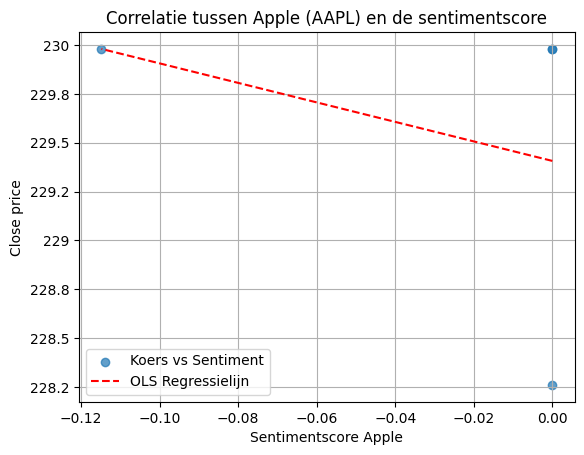

In [ ]:
from matplotlib.ticker import FuncFormatter

# Maak de scatter plot om de correlatie weer te geven
#plt.figure(figsize=(10, 6))
plt.scatter(combined_df["VA Score"], combined_df['AAPL'], alpha=0.7, label="Koers vs Sentiment")

# Voeg de regressielijn toe (de voorspellingen van de OLS-regressie)
plt.plot(combined_df["VA Score"], results.fittedvalues, "r--", label="OLS Regressielijn")

# Gebruik een FuncFormatter om het decimale getal op de y-as weg te laten als het 0 is en af te ronden op 1 decimaal
def remove_zero_formatter(x, pos):
    return f'{x:.1f}' if not x.is_integer() else f'{x:.0f}'

# Pas de formatter toe op de y-as
plt.gca().yaxis.set_major_formatter(FuncFormatter(remove_zero_formatter))

# Grafiekinstellingen
plt.title("Correlatie tussen Apple (AAPL) en de sentimentscore")
plt.xlabel("Sentimentscore Apple")
plt.ylabel("Close price")
plt.legend()
plt.grid(True)
plt.show()

We hebben in het voorgaande de tijdstippen op een dag weggehaald, maar via de optie 'ticker.history' kun je ook koersen per een bepaald tijdstip per dag binnenhalen. Daarmee zou je kunnen kijken of er (op dagbasis) verband is tussen een nieuwsbericht (de sentimentscore daarvan) en de koers op dat tijdstip.

In [ ]:
ticker = yf.Ticker("AAPL")

data = ticker.history(interval="1h", start="2025-01-16", end="2025-01-21")
data_close = data['Close']
data_close

,Close
Datetime,
2025-01-16 09:30:00-05:00,232.817993
2025-01-16 10:30:00-05:00,230.585007
2025-01-16 11:30:00-05:00,230.919998
2025-01-16 12:30:00-05:00,229.190002
2025-01-16 13:30:00-05:00,229.175003
2025-01-16 14:30:00-05:00,229.024994
2025-01-16 15:30:00-05:00,228.240005
2025-01-17 09:30:00-05:00,230.384995
2025-01-17 10:30:00-05:00,231.281296


Zou zeggen: probeer het uit!

# Twitter Sentiment Analysis
https://www.geeksforgeeks.org/twitter-sentiment-analysis-using-python/<br>


In [ ]:
import re
import tweepy
from tweepy import OAuthHandler
from textblob import TextBlob

In [ ]:
class TwitterClient(object):
    '''
    Generic Twitter Class for sentiment analysis.
    '''
    def __init__(self):
        '''
        Class constructor or initialization method.
        '''
        # keys and tokens from the Twitter Dev Console
        consumer_key = 'XXXXXXXXXXXXXXXXXXXXXXXX'
        consumer_secret = 'XXXXXXXXXXXXXXXXXXXXXXXXXXXX'
        access_token = 'XXXXXXXXXXXXXXXXXXXXXXXXXXXX'
        access_token_secret = 'XXXXXXXXXXXXXXXXXXXXXXXXX'

        # attempt authentication
        try:
            # create OAuthHandler object
            self.auth = OAuthHandler(consumer_key, consumer_secret)
            # set access token and secret
            self.auth.set_access_token(access_token, access_token_secret)
            # create tweepy API object to fetch tweets
            self.api = tweepy.API(self.auth)
        except:
            print("Error: Authentication Failed")

    #def clean_tweet(self, tweet):
        '''
        Utility function to clean tweet text by removing links, special characters
        using simple regex statements.
        '''
        #return ' '.join(re.sub("(@[A-Za-z0-9]+)|([^0-9A-Za-z \t])
        #                           |(\w+:\/\/\S+)", " ", tweet).split())

    def get_tweet_sentiment(self, tweet):
        '''
        Utility function to classify sentiment of passed tweet
        using textblob's sentiment method
        '''
        # create TextBlob object of passed tweet text
        analysis = TextBlob(self.clean_tweet(tweet))
        # set sentiment
        if analysis.sentiment.polarity > 0:
            return 'positive'
        elif analysis.sentiment.polarity == 0:
            return 'neutral'
        else:
            return 'negative'

    def get_tweets(self, query, count = 10):
        '''
        Main function to fetch tweets and parse them.
        '''
        # empty list to store parsed tweets
        tweets = []

        try:
            # call twitter api to fetch tweets
            fetched_tweets = self.api.search(q = query, count = count)

            # parsing tweets one by one
            for tweet in fetched_tweets:
                # empty dictionary to store required params of a tweet
                parsed_tweet = {}

                # saving text of tweet
                parsed_tweet['text'] = tweet.text
                # saving sentiment of tweet
                parsed_tweet['sentiment'] = self.get_tweet_sentiment(tweet.text)

                # appending parsed tweet to tweets list
                if tweet.retweet_count > 0:
                    # if tweet has retweets, ensure that it is appended only once
                    if parsed_tweet not in tweets:
                        tweets.append(parsed_tweet)
                else:
                    tweets.append(parsed_tweet)

            # return parsed tweets
            return tweets

        except tweepy.TweepError as e:
            # print error (if any)
            print("Error : " + str(e))

In [ ]:
def main():
    # creating object of TwitterClient Class
    api = TwitterClient()
    # calling function to get tweets
    tweets = api.get_tweets(query = 'Donald Trump', count = 200)

    # picking positive tweets from tweets
    ptweets = [tweet for tweet in tweets if tweet['sentiment'] == 'positive']
    # percentage of positive tweets
    print("Positive tweets percentage: {} %".format(100*len(ptweets)/len(tweets)))
    # picking negative tweets from tweets
    ntweets = [tweet for tweet in tweets if tweet['sentiment'] == 'negative']
    # percentage of negative tweets
    print("Negative tweets percentage: {} %".format(100*len(ntweets)/len(tweets)))
    # percentage of neutral tweets
    print("Neutral tweets percentage: {} % \
        ".format(100*(len(tweets) -(len( ntweets )+len( ptweets)))/len(tweets)))

    # printing first 5 positive tweets
    print("\n\nPositive tweets:")
    for tweet in ptweets[:10]:
        print(tweet['text'])

    # printing first 5 negative tweets
    print("\n\nNegative tweets:")
    for tweet in ntweets[:10]:
        print(tweet['text'])

In [ ]:
if __name__ == "__main__":
    # calling main function
    main()

Andere opties:<br>
https://towardsdatascience.com/step-by-step-twitter-sentiment-analysis-in-python-d6f650ade58d <br>
https://www.analyticsvidhya.com/blog/2021/06/twitter-sentiment-analysis-a-nlp-use-case-for-beginners/ <br>
https://github.com/aswintechguy/Machine-Learning-Projects/tree/master/Twitter%20Sentiment%20Analysis%20-%20NLP